In [ ]:
from itertools import repeat
from more_itertools import flatten
import matplotlib.pyplot as pl
from numpy import asarray, diff, ones

def savefig(name):
    savename = f'{name}.png'
    pl.savefig(savename, dpi=300, bbox_inches='tight')
    print(f'Saved {savename}')

def plot_mass(names, mass_dict, stop=None, alpha=0.5, lines=('-',)):
    pl.close('all')

    lines = flatten(repeat(lines))

    mass = list(mass_dict.values())
    sl = slice(None)
    if stop is not None:
        end = next(i for i, t in enumerate(mass[0]['time']) if t >= stop)
        sl = slice(0, end)

    def plot_separate(title, ylabel, tag='', ext='', lim=None):
        for name in names:
            var = name + ext
            pl.figure()
            pl.title(title) # + ', ' + name)
            for i, (case, m) in enumerate(mass_dict.items()):
                ls = next(lines)
                days = m['time']
                if i == 0:
                    pl.plot([days[0], days[-1]], m[var][0]*ones(2), ls='--', color='k', lw=1.5, alpha=0.3)
                line, = pl.plot(days[sl], m[var][sl], ls=ls, label=f'{case}', alpha=alpha)
            pl.text(0.5, 0.9, name, transform=pl.gca().transAxes, ha='center', fontsize=12)
            pl.legend()
            pl.xlabel('Days')
            pl.ylabel(ylabel)
            if lim:
                pl.ylim(lim)
            savefig(f'{name}_{tag}')
            #savename = f'{name}_{tag}.pdf'
            #pl.savefig(savename)
            #print(f'Saved {savename}')

    def plot_joined(title, ylabel, ext=''):
        pl.figure()
        pl.title(title)
        for name in names:
            var = name + ext
            for case, m in mass_dict.items():
                ls = next(lines)
                pl.plot(m['time'][sl], m[var][sl], ls=ls, label=f'{case}', alpha=alpha)
        pl.text(0.5, 0.9, ', '.join(names), transform=pl.gca().transAxes, ha='center', fontsize=12)
        pl.legend()
        pl.xlabel('Days')
        pl.ylabel(ylabel)
        savefig(f'{title.replace(" ", "_")}_{name}')

    def plot_rel_diff(ylabel, ext='', lim=None):
        for name in names:
            pl.figure()
            var = name + ext
            pl.title(r'$\Delta m = (m^{n+1} - m^{n}) / m^{n+1} $')
            for case, m in mass_dict.items():
                arr = asarray(m[var])
                rel_diff = ( arr[sl][1:] - arr[sl][:-1] ) / arr[sl][1:]
                pl.plot(m['time'][sl][1:], rel_diff, ls=next(lines), label=case, alpha=alpha)
            pl.text(0.5, 0.9, name, transform=pl.gca().transAxes, ha='center', fontsize=12)
            pl.legend()
            pl.xlabel('Days')
            pl.ylabel(ylabel)
            if lim:
                pl.ylim(lim)
            savefig(f'rel_diff_{name}')

    ylabel = 'Reservoir tracer mass'
    title=r'$m_{res} = \sum_{i=grid} c_i \cdot V_{wat,i}$'
    plot_separate(title, ylabel, ext='_res', tag='res', lim=(6.1455e11, 6.15e11))

    ylabel = 'Total tracer mass'
    title=r'$m_{tot}^n = \sum_{i=grid} c_i^n \cdot V_{wat,i}^n + \sum_{k=0,n} m_{prod}^k - \sum_{k=0,n} m_{inj}^k$'    
    #title=r'$m_{tot}^n = \sum_{i=grid} c_i^n \cdot V_{wat,i}^n + \sum_{k=0,n} \sum_{i=wells} \Delta t^k Q_{out,i}^k c_i^k - \sum_{k=0,n} m_{inj}^k$'    
    plot_separate(title, ylabel, tag='tot', lim=(6.1455e11, 6.15e11))

    title = 'Injected tracer mass'   
    plot_joined(title, title, ext='_inj')

    title = 'Produced tracer mass'
    plot_joined(title, title, ext='_prod')

    plot_rel_diff(ylabel='Relative difference in total mass', lim=(-1e-6, 2.3e-6))

    pl.figure()
    pl.title('Time step')
    time = list(mass_dict.values())[0]['time']
    pl.plot(time[1:], diff(time), alpha=alpha)    
    pl.xlabel('Days')
    pl.ylabel('Time step (days)')
    savefig('time_step')

    #plot_rel_diff(ylabel='Relative difference in res mass', ext='_res')


In [ ]:
# Read mass data from PySim output
from pathlib import Path
import matplotlib.pyplot as pl
import numpy as np

def read_mass_pysim(root, names):
    massfile = f'{root}_tracer_mass.dat'
    mass = np.genfromtxt(massfile, names=True)
    mass_py = {name: mass[name] for name in mass.dtype.names}
    tot = {name: mass[name+'_res'] + np.cumsum(mass[name+'_prod']) - np.cumsum(mass[name+'_inj']) for name in names}
    #tot = {name: mass[name+'_res'] + np.cumsum(mass[name+'_prod']) for name in names}
    mass_py.update(tot)
    return mass_py


In [ ]:
# Calculate mass for pySim
import numpy as np
from IORlib.ECL import UNRST_file
from IORlib.Flow import Flow, unrstfile
from ior2ecl import Output

def calc_mass_pysim(root, inj=None, tag='', acc=1e-3):
    out = Output(root)
    unrst = unrstfile(root)
    if tag:
        unrst = UNRST_file(unrst.path.parent/(unrst.path.stem + tag + unrst.path.suffix))
    py_data = unrst.blockdata('DOUBHEAD', 0, 'CL')
    ix_data = out.slb_unrst.blockdata('DOUBHEAD', 0, 'SWAT', 'RPORV')
    # Skip initialization
    next(py_data)
    next(ix_data)

    flow = Flow(root)
    well_data = flow.wells()
    time_old = 0
    mass = []
    inj_conc = inj
    for (time_py, *ior_val), (time_ix, *ix_val), wells in zip(py_data, ix_data, well_data):
        if abs(time_py - time_ix) > 1e-6:
            raise ValueError(f'Time mismatch: {time_py} != {time_ix}')
        dt = time_py - time_old
        time_old = time_py
        #print(f'{time_py.item()}, {time_ix.item()}')
        cl_ior, = unrst.reshape_dim(*ior_val)
        swat, rporv = unrst.reshape_dim(*ix_val)
        wrate = flow.wellrate(wells)
        if abs(time_py - wrate.time) > acc:
            raise ValueError(f'Time mismatch for wells: {time_py} != {wrate.time}')
        res_ior = np.sum(cl_ior * swat * rporv, axis=(0, 1, 2))
        if inj is None:
            inj_conc = cl_ior
        inj_ior = np.sum(dt * wrate.rate_in * inj_conc, axis=(0, 1, 2))
        prod_ior = np.sum(dt * wrate.rate_out * cl_ior, axis=(0, 1, 2))
        mass.append((time_py, res_ior, inj_ior, prod_ior))

    time, mass_res, mass_inj, mass_prod = zip(*mass)
    tot = np.array(mass_res) + np.cumsum(mass_prod) - np.cumsum(mass_inj)
    #tot = np.array(mass_res) + np.cumsum(np.array(mass_prod) - np.array(mass_inj))
    mass_ior = {'time':time, 'CL_res':mass_res, 'CL_inj':mass_inj, 'CL_prod':mass_prod, 'CL':tot}
    return mass_ior

In [ ]:
# Calculate mass for IORsim
import numpy as np
from IORlib.ECL import UNRST_file
from IORlib.Flow import Flow
from ior2ecl import Output

def calc_mass_iorsim(root, inj=None, tag='', acc=1e-3):
    out = Output(root)
    unrst = out.ior_unrst
    if tag:
        unrst = UNRST_file(unrst.path.parent/(unrst.path.stem + tag + unrst.path.suffix))
    ior_data = unrst.blockdata('DOUBHEAD', 0, 'CL')
    ix_data = out.slb_unrst.blockdata('DOUBHEAD', 0, 'SWAT', 'RPORV')
    # Skip initialization
    next(ior_data)
    next(ix_data)

    flow = Flow(root)
    well_data = flow.wells()
    time_old = 0
    mass = []
    inj_conc = inj
    for (time_ior, *ior_val), (time_ix, *ix_val), wells in zip(ior_data, ix_data, well_data):
        if abs(time_ior - time_ix) > 1e-6:
            raise ValueError(f'Time mismatch: {time_ior} != {time_ix}')
        dt = time_ior - time_old
        time_old = time_ior
        cl_ior, = unrst.reshape_dim(*ior_val)
        swat, rporv = unrst.reshape_dim(*ix_val)
        wrate = flow.wellrate(wells)
        if abs(time_ior - wrate.time) > acc:
            raise ValueError(f'Time mismatch for wells: {time_ior} != {wrate.time}')
        res_ior = np.sum(cl_ior * swat * rporv, axis=(0, 1, 2))
        if inj is None:
            inj_conc = cl_ior
        inj_ior = np.sum(dt * wrate.rate_in * inj_conc, axis=(0, 1, 2))
        prod_ior = np.sum(dt * wrate.rate_out * cl_ior, axis=(0, 1, 2))
        mass.append((time_ior, res_ior, inj_ior, prod_ior))

    time, mass_res, mass_inj, mass_prod = zip(*mass)
    tot = np.array(mass_res) + np.cumsum(mass_prod) - np.cumsum(mass_inj)
    mass_ior = {'time':time, 'CL_res':mass_res, 'CL_inj':mass_inj, 'CL_prod':mass_prod, 'CL':tot}
    return mass_ior

In [ ]:
# Calculate mass for Intersect
import numpy as np
from IORlib.Flow import Flow
from ior2ecl import Output

def calc_mass_intersect(root, inj=None, acc=1e-3):
    out = Output(root)
    unrst = out.slb_unrst
    ix_data = unrst.blockdata('DOUBHEAD', 0, 'SWAT', 'RPORV', 'TRCL')
    # Skip initialization
    next(ix_data)

    flow = Flow(root)
    well_data = flow.wells()
    time_old = 0
    mass = []
    inj_conc = inj
    for (time_ix, *val_ix), wells in zip(ix_data, well_data):
        dt = time_ix - time_old
        time_old = time_ix
        swat, rporv, cl_ix = unrst.reshape_dim(*val_ix)
        wrate = flow.wellrate(wells)
        if abs(time_ix - wrate.time) > acc:
            raise ValueError(f'Time mismatch: {time_ix} != {wrate.time}')
        #print(f'{time_ix.item()}, {wrate.time.item()}')
        res_ix = np.sum(cl_ix * swat * rporv, axis=(0, 1, 2))
        if inj is None:
            inj_conc = cl_ix
        inj_ix = np.sum(dt * wrate.rate_in * inj_conc, axis=(0, 1, 2))
        prod_ix = np.sum(dt * wrate.rate_out * cl_ix, axis=(0, 1, 2))
        mass.append((time_ix, res_ix, inj_ix, prod_ix))

    time, mass_res, mass_inj, mass_prod = zip(*mass)
    tot = np.array(mass_res) + np.cumsum(mass_prod) - np.cumsum(mass_inj)
    mass_ix = {'time':time, 'CL_res':mass_res, 'CL_inj':mass_inj, 'CL_prod':mass_prod, 'CL':tot}
    return mass_ix

In [7]:
# Calculate mass conservation for PySim, IORsim, and Intersect
from pathlib import Path

cop = Path.home() / 'CoP_files'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#root = cop/'input/Model_From_IXF/Model_From_IXF'
inj_conc = 0.56

print('PySim')
mass_py = calc_mass_pysim(root, inj=inj_conc) #, tag='_FLOAT')
print('IORSim')
mass_ior = calc_mass_iorsim(root, inj=inj_conc, tag='_JLV')
#mass_ior2 = calc_mass_iorsim(root, inj=inj_conc)
print('Intersect')
mass_ix = calc_mass_intersect(root, inj=inj_conc) #, tag='_7271days')

PySim
IORSim
Intersect


In [ ]:
#mass_py2 = calc_mass_pysim(root, inj=inj_conc)
mass_py_file = read_mass_pysim(root, ['CL'])

In [ ]:
# Plot mass conservation data
%matplotlib widget
plot_mass(('CL',), {'ior':mass_ior, 'py':mass_py, 'ix':mass_ix}, lines=('-', '-', '-'), alpha=0.75)
#plot_mass(('CL',), {'ior':mass_ior, 'py (float)':mass_py, 'py (double)':mass_py_file}, lines=('-', '-', '-'), alpha=0.75)
#plot_mass(('CL',), {'ix':mass_ix, 'py (float)':mass_py, 'py (double)':mass_py_file}, lines=('-',), alpha=0.75)

In [ ]:
# Calculate low/high limits for tracer concentration

from pathlib import Path
from IORlib.Flow import unrstfile
from IORlib.ECL import UNRST_file
from ior2ecl import Output
import numpy as np

cop = Path.home() / 'CoP_files'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'


def low_high(unrst, key, tag=''):
    if tag:
        unrst = UNRST_file(unrst.path.parent/(unrst.path.stem + tag + unrst.path.suffix))
    time, low, high = [], [], []
    print(f'Calculating low/high for {key} in {unrst}')
    for days, cl in unrst.blockdata('DOUBHEAD', 0, key):
        time.append(days.item())
        high.append(np.max(cl))
        low.append(np.min(cl))
    return {'time': time, 'low': low, 'high': high}

cop = Path.home() / 'CoP_files'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
out = Output(root)

ior_lim = low_high(out.ior_unrst, 'CL', tag='_JLV')
ior_lim2 = low_high(out.ior_unrst, 'CL')
ix_lim = low_high(out.slb_unrst, 'TRCL', tag='_7271days')
py_lim = low_high(unrstfile(root), 'CL', tag='_FLOAT')

In [ ]:
py_lim2 = low_high(unrstfile(root), 'CL')
#ix_lim3 = low_high(out.slb_unrst, 'TRCL')

In [ ]:
# Plot low/high limits
import matplotlib.pyplot as pl
%matplotlib widget

alpha = 0.75
pl.close('all')

pl.figure()
pl.title('Max tracer concentration')
pl.plot(ix_lim['time'], ix_lim['high'], label='IX', alpha=alpha)
pl.plot(py_lim['time'], py_lim['high'], label='PySim', alpha=alpha)
pl.plot(ior_lim['time'], np.minimum(ior_lim['high'], 7), label='IORsim', alpha=alpha)
#pl.plot(py_lim2['time'], py_lim2['high'], label='PySim2', alpha=alpha)
#pl.plot(ix_lim3['time'], ix_lim3['high'], label='IX3', alpha=alpha)
#pl.plot(ior_lim2['time'], np.minimum(ior_lim2['high'], 7), label='IORsim2')
pl.legend()
pl.xlabel('Days')
pl.ylabel('Tracer concentration')
pl.savefig('max_tracer_concentration.pdf')

pl.figure()
pl.title('Min tracer concentration')
pl.plot(ix_lim['time'], ix_lim['low'], label='IX', alpha=alpha)
pl.plot(py_lim['time'], py_lim['low'], label='PySim', alpha=alpha)
pl.plot(ior_lim['time'], ior_lim['low'], label='IORsim', alpha=alpha)
#pl.plot(py_lim2['time'], py_lim2['low'], label='PySim2', alpha=alpha)
#pl.plot(ix_lim3['time'], ix_lim3['low'], label='IX3', alpha=alpha)
#pl.plot(ior_lim2['time'], ior_lim2['low'], label='IORsim2')
pl.legend()
pl.xlabel('Days')
pl.ylabel('Tracer concentration')
pl.savefig('min_tracer_concentration.pdf')


In [ ]:
# Plot CPU time
py_data = np.genfromtxt(f'{root}_tracer_mass.dat', names=True)
pl.close('all')
pl.figure('CPU-time')
pl.plot(py_data['time'][1:], np.diff(py_data['cputime']))
pl.xlabel('Days')
pl.ylabel('CPU time (s)')

In [9]:
import numpy as np

out = Output(root)
unrst = out.slb_unrst
#unrst = out.ior_unrst
#tag = '_JLV'
#unrst = UNRST_file(unrst.path.parent/(unrst.path.stem + tag + unrst.path.suffix))
#unrst = unrstfile(root)
data = unrst.blockdata('DOUBHEAD', 0, 'TRCL')
#data = unrst.blockdata('DOUBHEAD', 0, 'CL')
# Skip initialization
next(data)

lims = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5)
below = []
days = []
#cells = 
for time_ix, cl in data:
    days.append(time_ix.item())
    below.append([np.count_nonzero(cl <= lim) for lim in lims])

below = np.array(below).T

Saved tracer_below_IX.png


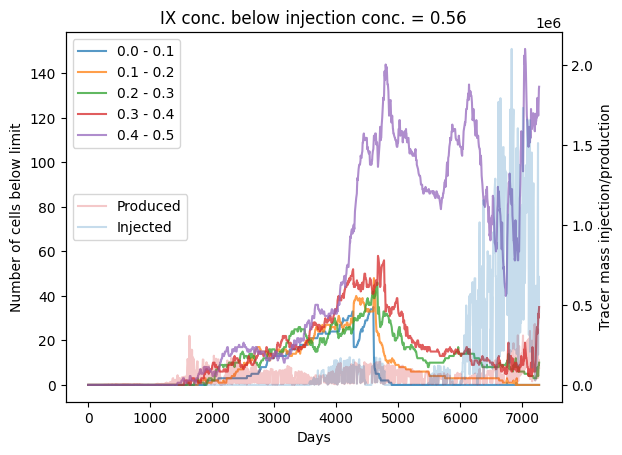

In [17]:
pl.figure()
pl.title('IX conc. below injection conc. = 0.56')
for i in range(len(lims)-1):
    pl.plot(days, below[i+1] - below[i], label=f'{lims[i]} - {lims[i+1]}', alpha=0.75)
pl.xlabel('Days')
pl.ylabel('Number of cells below limit')
pl.legend()
ax = pl.gca()
ax2 = ax.twinx()
ax2.plot(mass_ix['time'], mass_ix['CL_prod'], color='tab:red', label='Produced', alpha=0.25)
ax2.plot(mass_ix['time'], mass_ix['CL_inj'], color='tab:blue', label='Injected', alpha=0.25)
ax2.set_ylabel('Tracer mass injection/production')
ax2.legend(loc='center left')
savefig('tracer_below_IX')


In [ ]:
from math import prod


prod(unrst.dim())